Q13: Time Series Data Analysis

Analyzing stock prices over time.

Use Stock_Prices.csv from the same folder. This is the existing generated practice dataset, not real observations.

Weekday returns and monthly averages explore possible seasonal patterns. One year of practice data cannot confirm repeated annual seasonality. Simple exponential smoothing produces a constant multi-step forecast, fitted only on the training period.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Stock_Prices.csv")
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").set_index("Date")

print(df.head())
df.info()
print("Missing Values:")
print(df.isnull().sum())

             Close  Volume  MarketIndex
Date                                   
2024-01-01  102.97  325195     17998.28
2024-01-02  105.27  309874     18004.02
2024-01-03  105.72  106315     17993.29
2024-01-04  106.59  208729     18085.50
2024-01-05  106.40  333653     18070.59
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 260 entries, 2024-01-01 to 2024-12-27
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Close        260 non-null    float64
 1   Volume       260 non-null    int64  
 2   MarketIndex  260 non-null    float64
dtypes: float64(2), int64(1)
memory usage: 8.1 KB
Missing Values:
Close          0
Volume         0
MarketIndex    0
dtype: int64


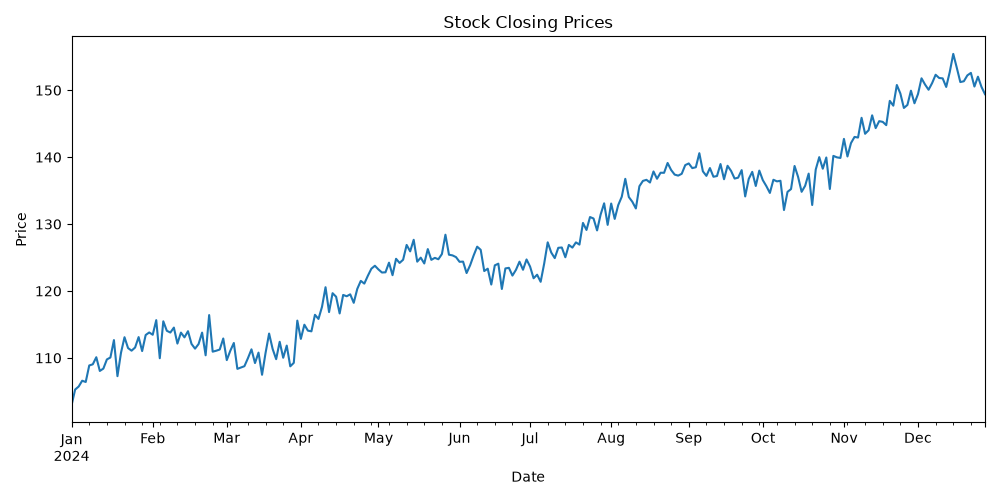

In [2]:
# Historical closing prices
df["Close"].plot(figsize=(10, 5))
plt.title("Stock Closing Prices")
plt.xlabel("Date")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

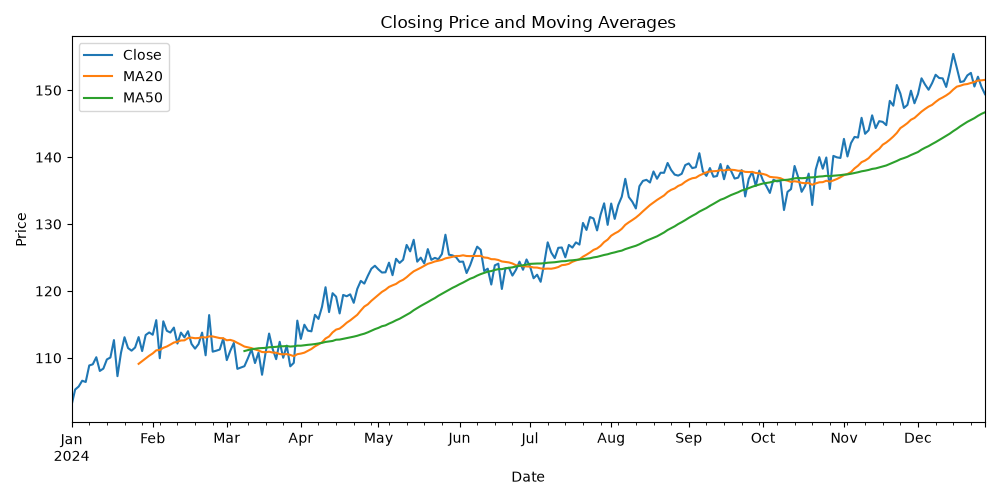

In [3]:
# Moving averages
df["MA20"] = df["Close"].rolling(window=20).mean()
df["MA50"] = df["Close"].rolling(window=50).mean()

df[["Close", "MA20", "MA50"]].plot(figsize=(10, 5))
plt.title("Closing Price and Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

Average Daily Return (%):
Date
Monday      -0.042060
Tuesday      0.528228
Wednesday   -0.118768
Thursday    -0.171455
Friday       0.587864
Name: Close, dtype: float64


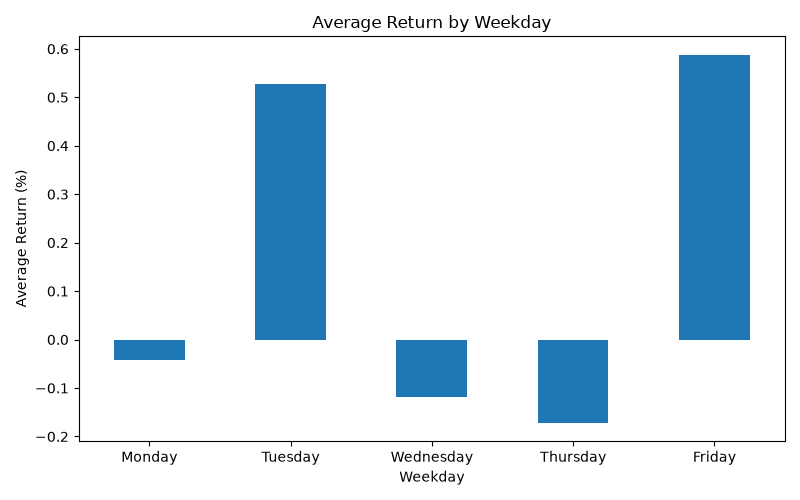

In [4]:
# Average daily return by weekday
returns = df["Close"].pct_change()
weekday_returns = returns.groupby(df.index.day_name()).mean()
weekday_returns = weekday_returns.reindex([
    "Monday", "Tuesday", "Wednesday", "Thursday", "Friday"
]) * 100
print("Average Daily Return (%):")
print(weekday_returns)

weekday_returns.plot(kind="bar", figsize=(8, 5))
plt.title("Average Return by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Average Return (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Monthly Average Price:
Date
2024-01-01    109.585652
2024-02-01    112.958571
2024-03-01    110.513333
2024-04-01    118.510455
2024-05-01    124.925217
2024-06-01    123.669000
2024-07-01    127.022609
2024-08-01    135.920909
2024-09-01    137.650476
2024-10-01    136.816957
2024-11-01    145.705238
2024-12-01    151.547000
Freq: MS, Name: Close, dtype: float64


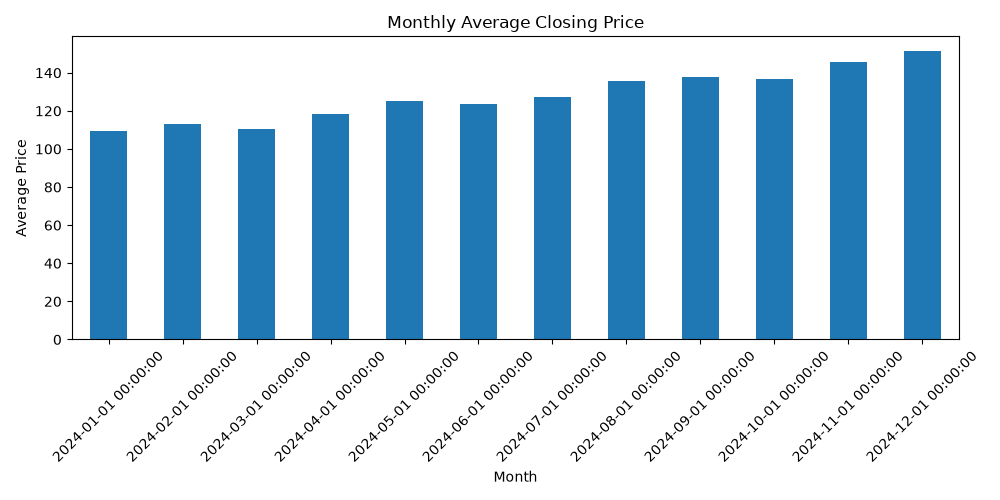

In [5]:
# Average closing price by month
monthly = df["Close"].resample("MS").mean()
print("Monthly Average Price:")
print(monthly)

monthly.plot(kind="bar", figsize=(10, 5))
plt.title("Monthly Average Closing Price")
plt.xlabel("Month")
plt.ylabel("Average Price")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

                Close    Volume  MarketIndex
Close        1.000000 -0.060337     0.914943
Volume      -0.060337  1.000000    -0.061249
MarketIndex  0.914943 -0.061249     1.000000


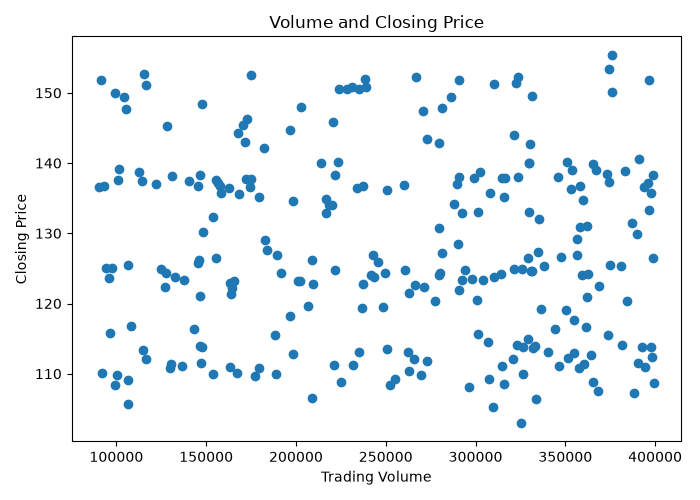

In [6]:
# Correlations between price, volume and market index
print(df[["Close", "Volume", "MarketIndex"]].corr())

plt.figure(figsize=(7, 5))
plt.scatter(df["Volume"], df["Close"])
plt.title("Volume and Closing Price")
plt.xlabel("Trading Volume")
plt.ylabel("Closing Price")
plt.tight_layout()
plt.show()

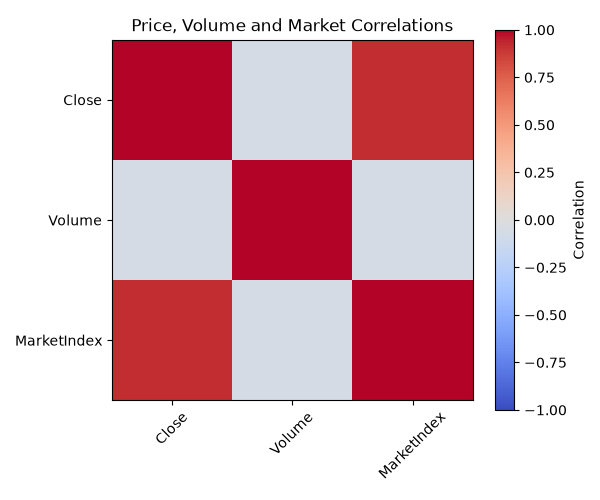

In [7]:
# Plot the correlation matrix
correlation = df[["Close", "Volume", "MarketIndex"]].corr()
plt.figure(figsize=(6, 5))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(3), correlation.columns, rotation=45)
plt.yticks(range(3), correlation.columns)
plt.colorbar(label="Correlation")
plt.title("Price, Volume and Market Correlations")
plt.tight_layout()
plt.show()

In [8]:
# Forecast using simple exponential smoothing
train = df["Close"].iloc[:-30]
test = df["Close"].iloc[-30:]

smoothed = train.ewm(alpha=0.3, adjust=False).mean()
forecast = pd.Series(smoothed.iloc[-1], index=test.index)

print("Forecast and Actual Prices:")
print(pd.DataFrame({"Actual": test, "Forecast": forecast}).head())
mae = (test - forecast).abs().mean()
print("\nMean Absolute Error:", round(mae, 2))

Forecast and Actual Prices:
            Actual    Forecast
Date                          
2024-11-18  145.27  144.626343
2024-11-19  144.78  144.626343
2024-11-20  148.41  144.626343
2024-11-21  147.69  144.626343
2024-11-22  150.78  144.626343

Mean Absolute Error: 5.72


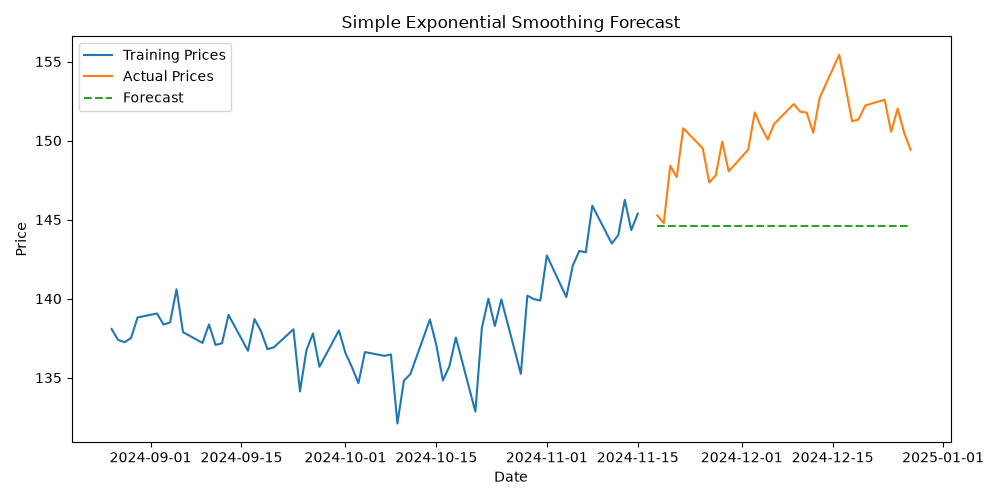

In [9]:
# Compare forecast with actual prices
plt.figure(figsize=(10, 5))
plt.plot(train.tail(60), label="Training Prices")
plt.plot(test, label="Actual Prices")
plt.plot(forecast, label="Forecast", linestyle="--")
plt.title("Simple Exponential Smoothing Forecast")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.tight_layout()
plt.show()